Mounted at /content/drive
Dataset caricato con successo.
Inizio Nested LOSO Cross-Validation...
Fold 1 (User debora): F1=0.8961 | Migliori Parametri: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 50, 'bootstrap': True}
Fold 2 (User jose_carlos): F1=0.9187 | Migliori Parametri: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': None, 'bootstrap': True}
Fold 3 (User katia): F1=0.6982 | Migliori Parametri: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'bootstrap': True}
Fold 4 (User wallace): F1=0.8771 | Migliori Parametri: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': None, 'bootstrap': True}

--- RISULTATI FINALI ---
F1-Score Medio: 0.8475
Configurazione più frequente (1 volte):
{'bootstrap': True, 'max_depth': 50, 'max_features': 'sqrt', 'min_samples_

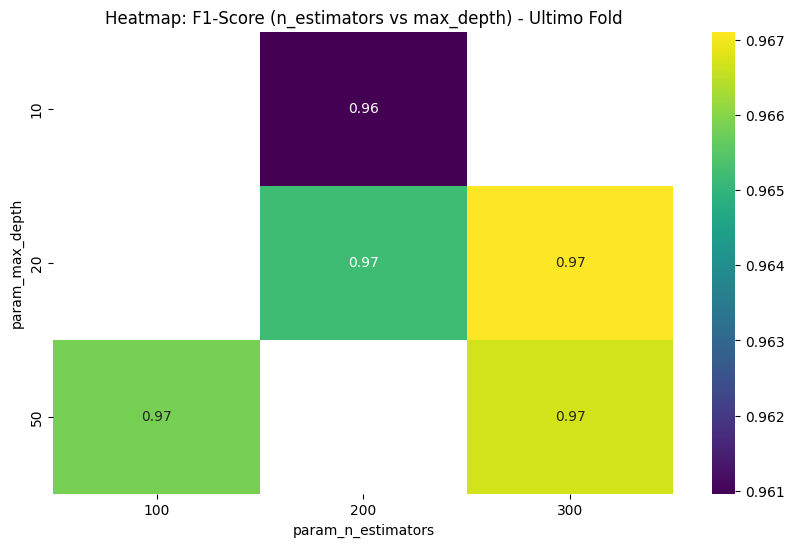


Generazione Validation Curve (n_estimators)...


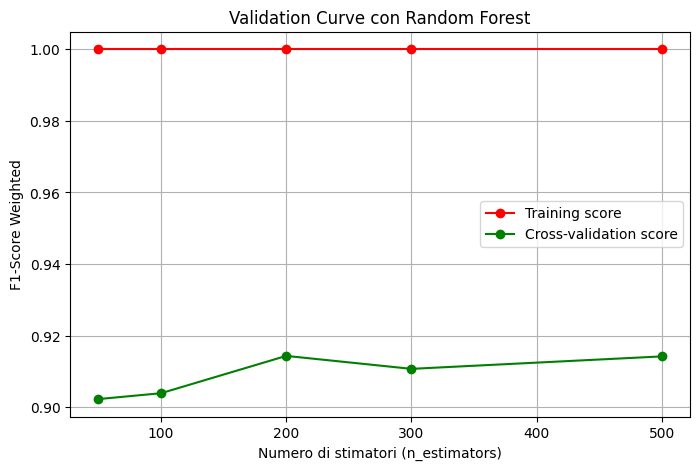

In [1]:
import pandas as pd
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut, validation_curve
from collections import Counter

# Mount Google Drive
drive.mount('/content/drive')

# --- CARICAMENTO DATI ---
dataset_path = '/content/drive/MyDrive/Colab/windowed.csv'
try:
    df = pd.read_csv(dataset_path)
    print("Dataset caricato con successo.")
except FileNotFoundError:
    print(f"Errore: Il file '{dataset_path}' non è stato trovato.")
    df = None

if df is not None:
    windowed_df = df.copy()
    if 'class' in windowed_df.columns and 'user' in windowed_df.columns:
        X_windowed = windowed_df.drop(columns=['class', 'user'])
        y_windowed = windowed_df['class']
        groups = windowed_df['user']
    else:
        print("Errore: Colonne 'class' o 'user' mancanti.")
        X_windowed = None

# --- NESTED LOSO CV MANUALE ---
if X_windowed is not None:
    print("Inizio Nested LOSO Cross-Validation...")

    param_dist_rf = {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [None, 10, 20, 30, 50],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2'],
        'bootstrap': [True, False]
    }

    loso = LeaveOneGroupOut()
    best_params_per_fold = []
    nested_f1_scores = []

    # Per la heatmap finale, memorizzeremo i risultati di tutti i tuning
    all_cv_results = []

    # Loop manuale per l'Outer CV (LOSO)
    fold = 1
    for train_idx, test_idx in loso.split(X_windowed, y_windowed, groups=groups):
        X_train, X_test = X_windowed.iloc[train_idx], X_windowed.iloc[test_idx]
        y_train, y_test = y_windowed.iloc[train_idx], y_windowed.iloc[test_idx]

        # Inner CV: Randomized Search
        inner_cv = 3
        random_search = RandomizedSearchCV(
            estimator=RandomForestClassifier(random_state=42),
            param_distributions=param_dist_rf,
            n_iter=10,
            cv=inner_cv,
            scoring='f1_weighted',
            n_jobs=-1,
            random_state=42
        )

        random_search.fit(X_train, y_train)

        # Salvataggio risultati
        best_params = random_search.best_params_
        best_params_per_fold.append(best_params)
        all_cv_results.append(pd.DataFrame(random_search.cv_results_))

        # Valutazione sul test set (l'utente lasciato fuori)
        y_pred = random_search.predict(X_test)
        score = f1_score(y_test, y_pred, average='weighted')
        nested_f1_scores.append(score)

        print(f"Fold {fold} (User {groups.iloc[test_idx].unique()[0]}): F1={score:.4f} | Migliori Parametri: {best_params}")
        fold += 1

    # --- ANALISI PARAMETRI MIGLIORI ---
    # Trasformiamo i dizionari in tuple per poterli contare
    param_tuples = [tuple(sorted(d.items())) for d in best_params_per_fold]
    most_common_tuple = Counter(param_tuples).most_common(1)[0]
    best_overall_params = dict(most_common_tuple[0])

    print("\n--- RISULTATI FINALI ---")
    print(f"F1-Score Medio: {np.mean(nested_f1_scores):.4f}")
    print(f"Configurazione più frequente ({most_common_tuple[1]} volte):")
    print(best_overall_params)

    # --- 1. HEATMAP DEL TUNING (Basata sull'ultimo fold) ---
    plt.figure(figsize=(10, 6))
    # Creiamo un dataframe con i risultati dell'ultimo search per visualizzare l'interazione
    results_df = all_cv_results[-1]
    # Pivot per la heatmap (usiamo n_estimators e max_depth come assi)
    # Nota: se alcuni valori mancano nel random search, appariranno come NaN
    viz_data = results_df.pivot_table(index='param_max_depth',
                                      columns='param_n_estimators',
                                      values='mean_test_score')
    sns.heatmap(viz_data, annot=True, cmap='viridis')
    plt.title('Heatmap: F1-Score (n_estimators vs max_depth) - Ultimo Fold')
    plt.show()

    # --- 2. VALIDATION CURVE ---
    # Visualizziamo come varia il punteggio al variare di 'n_estimators' sull'intero dataset
    print("\nGenerazione Validation Curve (n_estimators)...")
    param_range = [50, 100, 200, 300, 500]
    train_scores, test_scores = validation_curve(
        RandomForestClassifier(random_state=42),
        X_windowed, y_windowed,
        param_name="n_estimators",
        param_range=param_range,
        cv=3, scoring="f1_weighted", n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    plt.figure(figsize=(8, 5))
    plt.plot(param_range, train_mean, label="Training score", color="r", marker='o')
    plt.plot(param_range, test_mean, label="Cross-validation score", color="g", marker='o')
    plt.title("Validation Curve con Random Forest")
    plt.xlabel("Numero di stimatori (n_estimators)")
    plt.ylabel("F1-Score Weighted")
    plt.legend(loc="best")
    plt.grid()
    plt.show()

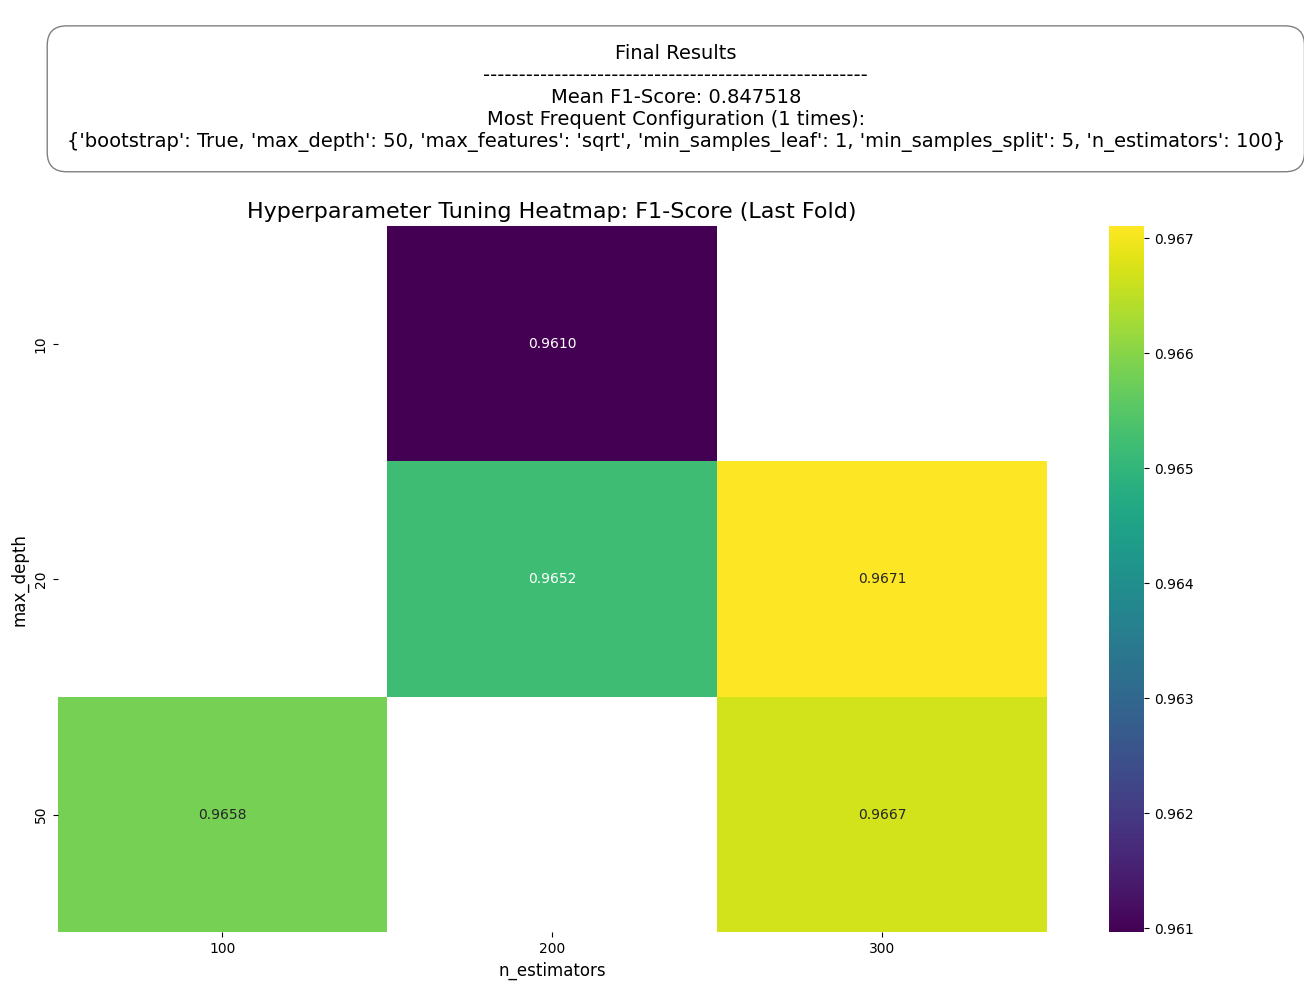

In [2]:
import matplotlib.gridspec as gridspec

# Create a figure with two subplots using GridSpec for better layout control
fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 4])

# 1. Text Summary for Best Configuration
ax0 = fig.add_subplot(gs[0])
ax0.axis('off')
summary_text = (
    f"Final Results\n"
    f"------------------------------------------------------\n"
    f"Mean F1-Score: {np.mean(nested_f1_scores):.6f}\n"
    f"Most Frequent Configuration ({most_common_tuple[1]} times):\n"
    f"{best_overall_params}"
)
ax0.text(0.5, 0.5, summary_text, ha='center', va='center', fontsize=14,
         bbox=dict(facecolor='white', alpha=0.5, boxstyle='round,pad=1'))

# 2. Detailed Heatmap from Last Fold
ax1 = fig.add_subplot(gs[1])
results_df = all_cv_results[-1]
viz_data = results_df.pivot_table(index='param_max_depth',
                                  columns='param_n_estimators',
                                  values='mean_test_score')

# Use fmt='.4f' for 4 decimal places in the heatmap
sns.heatmap(viz_data, annot=True, fmt='.4f', cmap='viridis', ax=ax1)
ax1.set_title('Hyperparameter Tuning Heatmap: F1-Score (Last Fold)', fontsize=16)
ax1.set_xlabel('n_estimators', fontsize=12)
ax1.set_ylabel('max_depth', fontsize=12)

plt.tight_layout()
plt.show()